#### Importing packages and specifying project root for modules and supporting datasets cleaning

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
from matplotlib.ticker import StrMethodFormatter

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.support_datasets_cleaning import (clean_support_df1,
                                           clean_support_df2,
                                           clean_support_df3,
                                           clean_support_df4)

DATA_DIR = PROJECT_ROOT / "data"
spdf1_path = DATA_DIR / "support_dataset1_data_job_wages.csv"
spdf2_path = DATA_DIR / "support_dataset2_quaterly_asking_rent.csv"
spdf3_path = DATA_DIR / "support_dataset3_average_rents_by_population.csv"
spdf4_path = DATA_DIR / "support_dataset4_overall_job_vacancies.csv"

spdf1_raw, spdf1_clean = clean_support_df1(spdf1_path)
spdf2_raw, spdf2_clean = clean_support_df2(spdf2_path)
spdf3_raw, spdf3_clean = clean_support_df3(spdf3_path)
spdf4_raw, spdf4_clean = clean_support_df4(spdf4_path)

#### Preview of the datasets (un-comment to see the top 5 entries per source)

In [57]:
# spdf1_clean.head(5)
# spdf2_clean.head(5)
# spdf3_clean.head(5)
# spdf4_clean.head(5)

### **Visualization 1 ("support_dataset1_data_job_wages"): Salary range comparison**

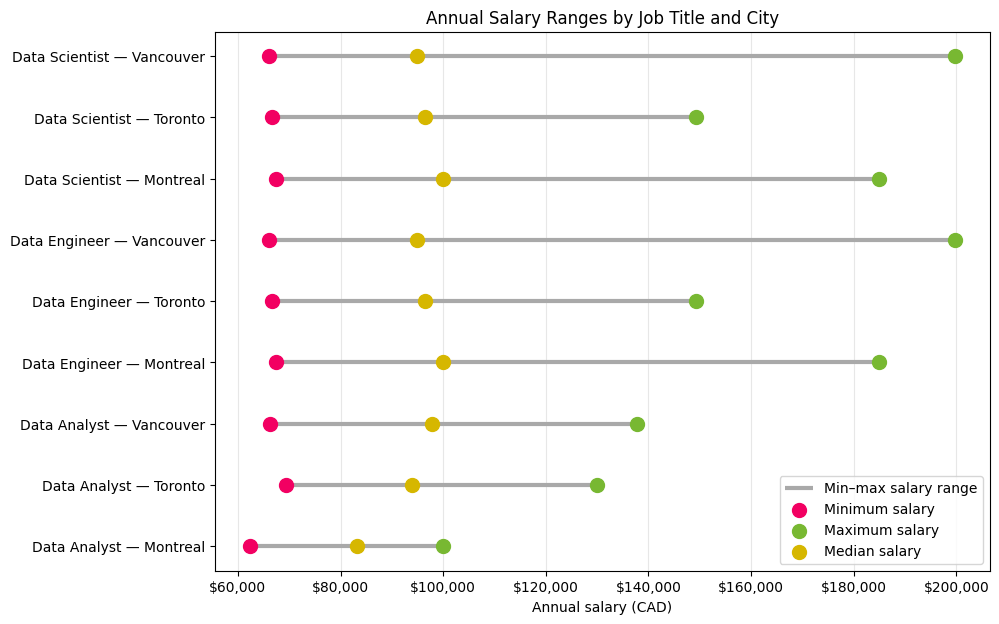

In [58]:
salary_plot = spdf1_clean.sort_values(["title", "city"])
fig, ax = plt.subplots(figsize=(10, 7))

for i, row in salary_plot.iterrows():

    ax.hlines(
        y=i,
        xmin=row["salary_min_annual"],
        xmax=row["salary_max_annual"],
        linewidth=3,
        colors="#A9A9A9",
        label="Min–max salary range" if i == 0 else None
        )

    ax.scatter(
        row["salary_min_annual"],
        i,
        color="#F20062",
        marker="o",
        s=100,
        zorder=3,
        label="Minimum salary" if i == 0 else None
        )

    ax.scatter(
        row["salary_max_annual"],
        i,
        color="#78B832",
        marker="o",
        s=100,
        zorder=3,
        label="Maximum salary" if i == 0 else None
        )

    ax.scatter(
        row["salary_mid_annual"],
        i,
        color="#D6B700",
        marker="o",
        s=100,
        zorder=3,
        label="Median salary" if i == 0 else None
        )

ax.set_yticks(range(len(salary_plot)))
ax.set_yticklabels(salary_plot["title"] + " — " + salary_plot["city"])
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Annual salary (CAD)")
ax.set_title("Annual Salary Ranges by Job Title and City")
ax.legend(loc='lower right')
ax.grid(axis="x", alpha=0.3)

plt.show()

### Visualization 2 ("support_dataset2_quaterly_asking_rent"): Quarterly rental price trends (method only)

In [59]:
def visualization2_specs(building_type, bedrooms):

    """
    Specify the building type from the entries available in the dataset (as text):
    - Apartment
    - House
    - Room

    And the number of bedrooms too (as number):
    - 0
    - 1
    - 2
    - 3
    """

    rent_plot = spdf2_clean.copy()
    rent_plot["year"] = rent_plot["quarter"].str[-4:].astype(int)
    rent_plot["quarter_number"] = (rent_plot["quarter"].str[1].astype(int))
    rent_plot["quarter_order"] = (rent_plot["year"] * 4 + rent_plot["quarter_number"])

    rent_plot = rent_plot[
        (rent_plot["building_type"] == building_type) &
        (rent_plot["bedrooms"] == bedrooms)
    ]

    quarter_labels = (
        rent_plot[["quarter", "quarter_order"]]
        .drop_duplicates()
        .sort_values("quarter_order")
    )

    fig, ax = plt.subplots(figsize=(12, 5))

    for city, group in rent_plot.groupby("city"):

        group = group.sort_values("quarter_order")

        ax.plot(
            group["quarter_order"],
            group["monthly_rent_cad"],
            marker="o",
            label=city
        )

    ax.set_xticks(quarter_labels["quarter_order"].iloc[::4])
    ax.set_xticklabels(
        quarter_labels["quarter"].iloc[::4],
        rotation=45,
        ha="right"
    )

    ax.set_xlabel("Quarter")
    ax.set_ylabel("Monthly Rent (CAD)")
    ax.set_title(f"Quarterly Rental Prices - {bedrooms}-Bedroom {building_type}"
                 if building_type != "Room" else f"Quarterly Rental Prices - {building_type}")
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.legend(title="City")
    ax.grid(alpha=0.3)

    return plt.show()

### **Visualization 2: Quarterly rental price trends (graph personalization)**

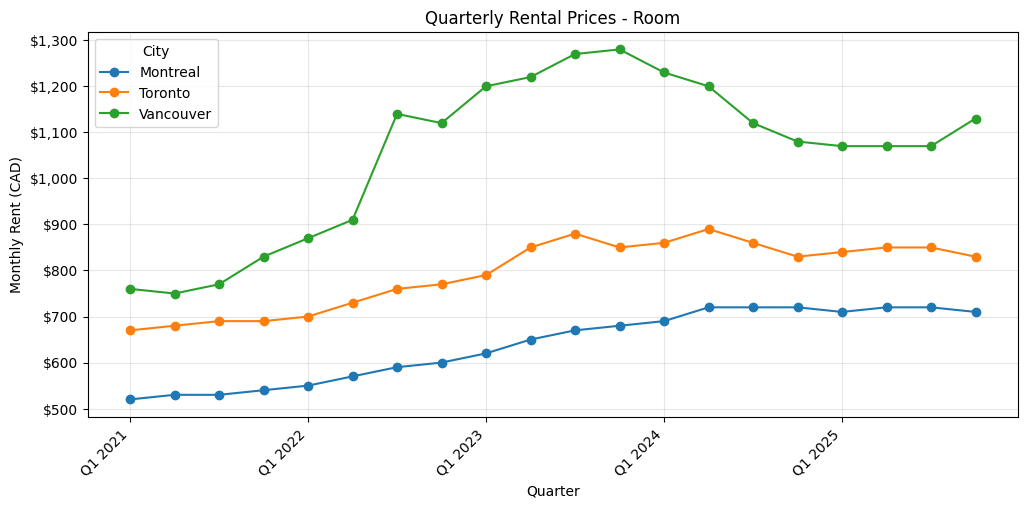

In [60]:
visualization2_specs("Room", 1)

### **Visualization 3 ("support_dataset3_average_rents_by_population"): Annual rental prices by building characteristics**

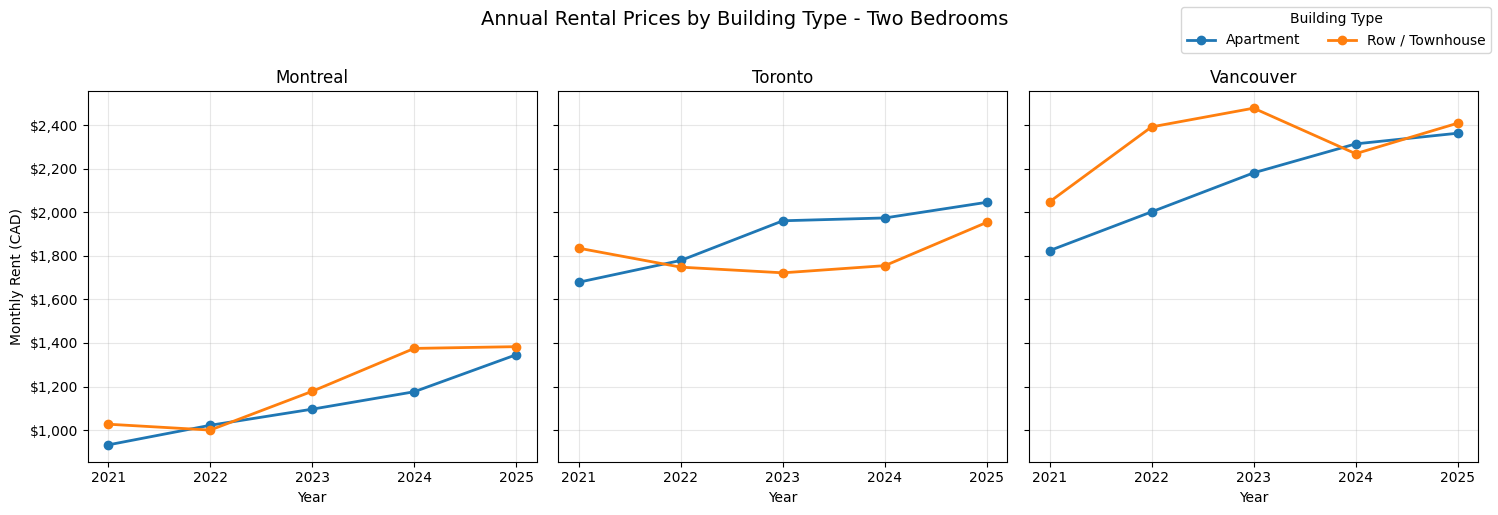

In [61]:
rent_plot = pd.read_csv(DATA_DIR / "support_dataset3_clean.csv")
categorical_cols = ["building_type", "building_structure", "city"]

for col in categorical_cols:
    rent_plot[col] = rent_plot[col].astype(str).str.strip()

rent_plot["bedrooms"] = pd.to_numeric(rent_plot["bedrooms"], errors="coerce")
rent_plot["year"] = pd.to_numeric(rent_plot["year"], errors="coerce")
rent_plot["monthly_rent_cad"] = pd.to_numeric(rent_plot["monthly_rent_cad"], errors="coerce")

# Filter two-bedroom units in buildings with three units and over
rent_trend = rent_plot[
    (rent_plot["building_structure"] == "Three units and over") &
    (rent_plot["bedrooms"] == 2)
].copy()

cities = ["Montreal", "Toronto", "Vancouver"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, city in zip(axes, cities):
    city_data = rent_trend[rent_trend["city"] == city]

    for building_type, group in city_data.groupby("building_type"):
        group = group.sort_values("year")
        ax.plot(
            group["year"],
            group["monthly_rent_cad"],
            marker="o",
            linewidth=2,
            label=building_type
            )

    ax.set_title(city)
    ax.set_xlabel("Year")
    ax.set_xticks([2021, 2022, 2023, 2024, 2025])
    ax.grid(axis="both", alpha=0.3)

axes[0].set_ylabel("Monthly Rent (CAD)")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Building Type",
    loc="upper right",
    ncol=2
    )

fig.suptitle("Annual Rental Prices by Building Type - Two Bedrooms", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### **Visualization 4 ("support_dataset4_overall_job_vacancies"): Job vacancies, payroll employees and offered wages**

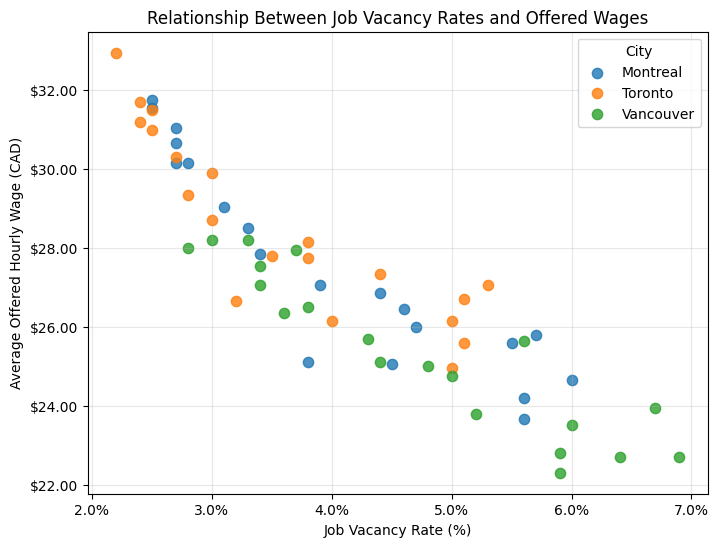

In [62]:
fig, ax = plt.subplots(figsize=(8, 6))

for city, group in spdf4_clean.groupby("city"):

    ax.scatter(
        group["job_vacancy_rate"],
        group["salary_average_hourly"],
        label=city,
        alpha=0.8,
        s=55
    )

ax.set_xlabel("Job Vacancy Rate (%)")
ax.set_ylabel("Average Offered Hourly Wage (CAD)")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:.1f}%"))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:.2f}"))
ax.set_title("Relationship Between Job Vacancy Rates and Offered Wages")
ax.legend(title="City")
ax.grid(alpha=0.3)

plt.show()